# HazeLightFormer: NHD Training and RESIDE / RESIDE-6K Testing

A Kaggle-ready notebook for joint image dehazing and low-light restoration. It preserves the proven NHD, RESIDE, and RESIDE-6K paired-data workflow from `ldformer.ipynb`, replacing only the network with HazeLightFormer.

## Setup Dependencies


In [1]:
%%capture
!pip -q install scikit-image --root-user-action=ignore

## Imports and Warning Control


In [2]:
import os
# Set before CUDA/PyTorch initialization; restart the Kaggle kernel, then Run All.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import json
import random
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## Configuration
Update only the dataset paths if your Kaggle input slugs differ. The required folder layout is unchanged from `nhdv2`.


In [3]:
@dataclass
class CFG:
    ROOT: str = "/kaggle/input/datasets/mouryavardhanrathod/nhd-dataset-v1/NHD"
    INDEX_FILE: str = ""
    RESIDE_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD/test"
    RESIDE6K_ROOT: str = "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset/test"

    # HazeLightFormer's rectangular attention needs dimensions divisible by WINDOW_SIZE.
    IMAGE_SIZE: int = 192
    BATCH_SIZE: int = 2
    ACCUM_STEPS: int = 4
    MODEL_DIM: int = 24
    WINDOW_SIZE: tuple = (8, 12)  # rectangular RWA / SRWA window (H, W)
    MODEL_BLOCKS: tuple = (2, 2, 4)
    EPOCHS: int = 100
    LR: float = 2e-4
    WEIGHT_DECAY: float = 1e-4
    PATIENCE: int = 12
    NUM_WORKERS: int = 2
    SEED: int = 42
    OUT_DIR: str = "/kaggle/working/hazelightformer_nhd"
    SELECTED_STRATEGIES: tuple = ("uniform", "fog_bank", "perlin", "radial", "depth_dep")

cfg = CFG()
cfg.INDEX_FILE = os.path.join(cfg.ROOT, "dataset_index.json")
os.makedirs(cfg.OUT_DIR, exist_ok=True)
assert cfg.IMAGE_SIZE % 4 == 0 and cfg.IMAGE_SIZE % cfg.WINDOW_SIZE[0] == 0 and cfg.IMAGE_SIZE % cfg.WINDOW_SIZE[1] == 0
print("Output dir:", cfg.OUT_DIR)

Output dir: /kaggle/working/hazelightformer_nhd


## NHD Dataset Loader
NHD training/validation/test splits come from `dataset_index.json`. RESIDE and reside-6k use paired image folders for external evaluation.


In [4]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
image_transform = transforms.Compose([
    transforms.Resize((cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)),
    transforms.ToTensor(),
])

def list_images(folder):
    if not folder or not os.path.isdir(folder):
        return []
    return sorted(
        os.path.join(root, name)
        for root, _, files in os.walk(folder)
        for name in files
        if name.lower().endswith(IMAGE_EXTENSIONS)
    )

def normalize_pair_stem(path):
    stem = os.path.splitext(os.path.basename(path))[0].lower()
    for token in ("_hazy", "-hazy", " haze", "_gt", "-gt", "_clean", "-clean", "_clear", "-clear"):
        stem = stem.replace(token, "")
    return stem

def build_image_pairs_from_folders(hazy_dir, gt_dir):
    hazy_paths, gt_paths = list_images(hazy_dir), list_images(gt_dir)
    gt_by_stem = {normalize_pair_stem(path): path for path in gt_paths}
    pairs = [(hazy, gt_by_stem[normalize_pair_stem(hazy)]) for hazy in hazy_paths if normalize_pair_stem(hazy) in gt_by_stem]
    return pairs or (list(zip(hazy_paths, gt_paths)) if len(hazy_paths) == len(gt_paths) else [])

def find_paired_root(preferred, alternatives):
    for root in (preferred, *alternatives):
        if os.path.isdir(os.path.join(root, "hazy")) and os.path.isdir(os.path.join(root, "gt")):
            return root
    return None

class PairedDehazeDataset(Dataset):
    def __init__(self, pairs, dataset_name):
        self.pairs, self.dataset_name = pairs, dataset_name

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        hazy_path, gt_path = self.pairs[idx]
        hazy = Image.open(hazy_path).convert("RGB")
        gt = Image.open(gt_path).convert("RGB")
        return {
            "hazy": image_transform(hazy),
            "gt": image_transform(gt),
            "dataset": self.dataset_name,
            "img_id": os.path.basename(hazy_path),
        }

def build_nhd_pairs(split):
    if not os.path.isfile(cfg.INDEX_FILE):
        raise FileNotFoundError(f"NHD index not found: {cfg.INDEX_FILE}")
    with open(cfg.INDEX_FILE, "r") as f:
        metadata = json.load(f)
    pairs = []
    for item in metadata:
        if item.get("split") != split or item.get("strategy") not in cfg.SELECTED_STRATEGIES:
            continue
        hazy = os.path.join(cfg.ROOT, item["hazy_path"])
        gt = os.path.join(cfg.ROOT, item["gt_path"])
        if os.path.isfile(hazy) and os.path.isfile(gt):
            pairs.append((hazy, gt))
    return pairs

train_dataset = PairedDehazeDataset(build_nhd_pairs("train"), "NHD_dataset")
val_dataset = PairedDehazeDataset(build_nhd_pairs("val"), "NHD_dataset")
test_dataset = PairedDehazeDataset(build_nhd_pairs("test"), "NHD_dataset")
assert len(train_dataset) and len(val_dataset) and len(test_dataset), "NHD split is empty; check cfg.ROOT."

def make_loader(dataset, shuffle=False):
    return DataLoader(dataset, batch_size=cfg.BATCH_SIZE, shuffle=shuffle, num_workers=cfg.NUM_WORKERS, pin_memory=torch.cuda.is_available())

train_loader, val_loader, test_loader = make_loader(train_dataset, True), make_loader(val_dataset), make_loader(test_dataset)
print(f"NHD pairs — train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")


NHD pairs — train: 560, val: 70, test: 70


## HazeLightFormer Architecture

HazeLightFormer is a joint dehazing/low-light Transformer with three stages: shallow convolutional extraction, hierarchical Joint Transformer Layer (JTL) encoding, and progressive restoration. Each JTL combines Rectangular Window Attention (RWA), Shifted RWA (SRWA), LayerNorm, MLP, and residual paths. Its Dual Upsampling Module (DUM) fuses a bilinear/PReLU branch with a learnable PixelShuffle/PReLU branch.

The paper describes these components and high-level hierarchy but does not publish source code or every hidden width/depth. The exposed settings make those implementation choices explicit and Kaggle-adjustable.

In [5]:
class LayerNorm2d(nn.Module):
    def __init__(self, channels, eps=1e-6):
        super().__init__()
        self.weight, self.bias, self.eps = nn.Parameter(torch.ones(channels)), nn.Parameter(torch.zeros(channels)), eps
    def forward(self, x):
        mean = x.mean(1, keepdim=True); var = (x - mean).pow(2).mean(1, keepdim=True)
        return (x - mean) / torch.sqrt(var + self.eps) * self.weight[:, None, None] + self.bias[:, None, None]


def partition_windows(x, window):
    b, c, h, w = x.shape; wh, ww = window
    assert h % wh == 0 and w % ww == 0, f'feature size {(h,w)} must divide window {window}'
    return x.view(b, c, h // wh, wh, w // ww, ww).permute(0, 2, 4, 3, 5, 1).reshape(-1, wh * ww, c)


def reverse_windows(windows, window, b, h, w, c):
    wh, ww = window
    return windows.view(b, h // wh, w // ww, wh, ww, c).permute(0, 5, 1, 3, 2, 4).reshape(b, c, h, w)


class RectangularWindowAttention(nn.Module):
    """RWA, or SRWA when shifted=True, as specified in the HazeLightFormer JTL."""
    def __init__(self, dim, heads, window=(8, 12), shifted=False):
        super().__init__()
        assert dim % heads == 0
        self.heads, self.window, self.shifted = heads, window, shifted
        self.qkv, self.proj = nn.Linear(dim, dim * 3), nn.Linear(dim, dim)
        self.scale = (dim // heads) ** -0.5

    def forward(self, x):
        b, c, h, w = x.shape; wh, ww = self.window
        shift = (wh // 2, ww // 2) if self.shifted else (0, 0)
        if self.shifted: x = torch.roll(x, shifts=(-shift[0], -shift[1]), dims=(2, 3))
        tokens = partition_windows(x, self.window); n = tokens.shape[1]
        q, k, v = self.qkv(tokens).reshape(-1, n, 3, self.heads, c // self.heads).permute(2, 0, 3, 1, 4)
        attention = (q @ k.transpose(-2, -1) * self.scale).softmax(dim=-1)
        tokens = self.proj((attention @ v).transpose(1, 2).reshape(-1, n, c))
        x = reverse_windows(tokens, self.window, b, h, w, c)
        return torch.roll(x, shifts=shift, dims=(2, 3)) if self.shifted else x


class MLP(nn.Module):
    def __init__(self, dim, expansion=2):
        super().__init__(); hidden = dim * expansion
        self.net = nn.Sequential(nn.Conv2d(dim, hidden, 1), nn.GELU(), nn.Conv2d(hidden, dim, 1))
    def forward(self, x): return self.net(x)


class JointTransformerLayer(nn.Module):
    """JTL: RWA + SRWA + MLP, each with LayerNorm and residual learning."""
    def __init__(self, dim, heads, window):
        super().__init__()
        self.norm_rwa, self.rwa = LayerNorm2d(dim), RectangularWindowAttention(dim, heads, window, shifted=False)
        self.norm_srwa, self.srwa = LayerNorm2d(dim), RectangularWindowAttention(dim, heads, window, shifted=True)
        self.norm_mlp, self.mlp = LayerNorm2d(dim), MLP(dim)
    def forward(self, x):
        x = x + self.rwa(self.norm_rwa(x))
        x = x + self.srwa(self.norm_srwa(x))
        return x + self.mlp(self.norm_mlp(x))


class JTLStack(nn.Module):
    def __init__(self, dim, blocks, heads, window):
        super().__init__(); self.blocks = nn.Sequential(*[JointTransformerLayer(dim, heads, window) for _ in range(blocks)])
    def forward(self, x): return self.blocks(x)


class Downsample(nn.Module):
    def __init__(self, dim): super().__init__(); self.body = nn.Conv2d(dim, dim * 2, 3, stride=2, padding=1)
    def forward(self, x): return self.body(x)


class DualUpsamplingModule(nn.Module):
    """Paper DUM: bilinear + PReLU branch fused with a PixelShuffle + PReLU branch."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.bilinear = nn.Sequential(nn.Conv2d(in_dim, out_dim, 3, padding=1), nn.PReLU(), nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False), nn.Conv2d(out_dim, out_dim, 3, padding=1))
        self.pixel_pre = nn.Sequential(nn.Conv2d(in_dim, out_dim * 4, 3, padding=1), nn.PReLU())
        self.pixel_post = nn.Sequential(nn.PixelShuffle(2), nn.Conv2d(out_dim, out_dim, 3, padding=1), nn.PReLU())
        self.fuse = nn.Conv2d(out_dim * 2, out_dim, 1)
    def forward(self, x):
        return self.fuse(torch.cat([self.bilinear(x), self.pixel_post(self.pixel_pre(x))], dim=1))


class HazeLightFormer(nn.Module):
    def __init__(self, dim=24, blocks=(2, 2, 4), window=(8, 12), heads=(2, 4, 4)):
        super().__init__()
        self.shallow = nn.Conv2d(3, dim, 3, padding=1)
        self.encoder1 = JTLStack(dim, blocks[0], heads[0], window)
        self.down1 = Downsample(dim)
        self.encoder2 = JTLStack(dim * 2, blocks[1], heads[1], window)
        self.down2 = Downsample(dim * 2)
        self.bottleneck = JTLStack(dim * 4, blocks[2], heads[2], window)
        self.dual_up2 = DualUpsamplingModule(dim * 4, dim * 2)
        self.decoder2 = JTLStack(dim * 2, blocks[1], heads[1], window)
        self.dual_up1 = DualUpsamplingModule(dim * 2, dim)
        self.decoder1 = JTLStack(dim, blocks[0], heads[0], window)
        self.output = nn.Conv2d(dim, 3, 3, padding=1)
        self.skip2, self.skip1 = nn.Conv2d(dim * 2, dim * 2, 1), nn.Conv2d(dim, dim, 1)

    def forward(self, degraded):
        e1 = self.encoder1(self.shallow(degraded))
        e2 = self.encoder2(self.down1(e1))
        x = self.bottleneck(self.down2(e2))
        x = self.decoder2(self.dual_up2(x) + self.skip2(e2))
        x = self.decoder1(self.dual_up1(x) + self.skip1(e1))
        return (degraded + self.output(x)).clamp(0.0, 1.0)


model = HazeLightFormer(dim=cfg.MODEL_DIM, blocks=cfg.MODEL_BLOCKS, window=cfg.WINDOW_SIZE).to(device)
print(model)
print(f'HazeLightFormer trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

HazeLightFormer(
  (shallow): Conv2d(3, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (encoder1): JTLStack(
    (blocks): Sequential(
      (0): JointTransformerLayer(
        (norm_rwa): LayerNorm2d()
        (rwa): RectangularWindowAttention(
          (qkv): Linear(in_features=24, out_features=72, bias=True)
          (proj): Linear(in_features=24, out_features=24, bias=True)
        )
        (norm_srwa): LayerNorm2d()
        (srwa): RectangularWindowAttention(
          (qkv): Linear(in_features=24, out_features=72, bias=True)
          (proj): Linear(in_features=24, out_features=24, bias=True)
        )
        (norm_mlp): LayerNorm2d()
        (mlp): MLP(
          (net): Sequential(
            (0): Conv2d(24, 48, kernel_size=(1, 1), stride=(1, 1))
            (1): GELU(approximate='none')
            (2): Conv2d(48, 24, kernel_size=(1, 1), stride=(1, 1))
          )
        )
      )
      (1): JointTransformerLayer(
        (norm_rwa): LayerNorm2d()
        (rwa):

## End-to-End Joint Training
Train LDFormer directly on NHD paired hazy/clean images. The checkpoint with the highest validation PSNR is retained.


In [6]:
def charbonnier_loss(pred, target, eps=1e-3):
    return torch.mean(torch.sqrt((pred - target).pow(2) + eps * eps))

def batch_psnr(pred, target, eps=1e-8):
    mse = (pred - target).pow(2).flatten(1).mean(1).clamp_min(eps)
    return (10.0 * torch.log10(1.0 / mse)).mean()

def batch_ssim(pred, target, eps=1e-8):
    """Dependency-free global SSIM for training diagnostics (higher is better)."""
    x, y = pred.flatten(1), target.flatten(1)
    mux, muy = x.mean(1), y.mean(1)
    vx, vy = x.var(1, unbiased=False), y.var(1, unbiased=False)
    cov = ((x - mux[:, None]) * (y - muy[:, None])).mean(1)
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    score = ((2 * mux * muy + c1) * (2 * cov + c2)) / ((mux.square() + muy.square() + c1) * (vx + vy + c2) + eps)
    return score.mean()

def loss_fn(pred, target):
    return charbonnier_loss(pred, target)

def evaluate(model, loader):
    model.eval(); losses, psnrs, ssims, maes = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            hazy = batch['hazy'].to(device, non_blocking=True)
            gt = batch['gt'].to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=amp_enabled):
                pred = model(hazy); loss = loss_fn(pred, gt)
            pred, gt = pred.float(), gt.float()
            losses.append(loss.float().item()); psnrs.append(batch_psnr(pred, gt).item()); ssims.append(batch_ssim(pred, gt).item()); maes.append(F.l1_loss(pred, gt).item())
    return {'loss': float(np.mean(losses)), 'psnr': float(np.mean(psnrs)), 'ssim': float(np.mean(ssims)), 'mae': float(np.mean(maes))}

amp_enabled = device.type == 'cuda'
scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=4)
history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_psnr': [], 'val_ssim': [], 'val_mae': []}
best_psnr, bad_epochs = -float('inf'), 0
checkpoint_path = os.path.join(cfg.OUT_DIR, 'best_hazelightformer_nhd.pth')

for epoch in range(cfg.EPOCHS):
    model.train(); train_losses = []; optimizer.zero_grad(set_to_none=True)
    for step, batch in enumerate(tqdm(train_loader, desc=f'Epoch {epoch + 1}/{cfg.EPOCHS}', leave=False), start=1):
        hazy = batch['hazy'].to(device, non_blocking=True); gt = batch['gt'].to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=amp_enabled):
            loss = loss_fn(model(hazy), gt)
        scaler.scale(loss / cfg.ACCUM_STEPS).backward(); train_losses.append(loss.float().item())
        if step % cfg.ACCUM_STEPS == 0 or step == len(train_loader):
            scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
    val = evaluate(model, val_loader); train_loss = float(np.mean(train_losses))
    history['epoch'].append(epoch + 1); history['train_loss'].append(train_loss); history['val_loss'].append(val['loss']); history['val_psnr'].append(val['psnr']); history['val_ssim'].append(val['ssim']); history['val_mae'].append(val['mae'])
    scheduler.step(val['psnr'])
    print(f"Epoch {epoch + 1:03d} | train={train_loss:.5f} | val_loss={val['loss']:.5f} | val_psnr={val['psnr']:.2f} | val_ssim={val['ssim']:.4f} | val_mae={val['mae']:.5f}")
    if val['psnr'] > best_psnr:
        best_psnr, bad_epochs = val['psnr'], 0; torch.save(model.state_dict(), checkpoint_path)
    else:
        bad_epochs += 1
        if bad_epochs >= cfg.PATIENCE:
            print('Early stopping.'); break

model.load_state_dict(torch.load(checkpoint_path, map_location=device))
print('Best validation PSNR:', f'{best_psnr:.2f}', '| checkpoint:', checkpoint_path)

Epoch 1/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 001 | train=0.14465 | val_loss=0.13409 | val_psnr=16.15 | val_ssim=0.6489 | val_mae=0.13408


Epoch 2/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 002 | train=0.13456 | val_loss=0.12127 | val_psnr=16.95 | val_ssim=0.7025 | val_mae=0.12125


Epoch 3/100:   0%|          | 0/280 [00:00<?, ?it/s]

Epoch 003 | train=0.12464 | val_loss=0.11049 | val_psnr=17.72 | val_ssim=0.7694 | val_mae=0.11047


... (102 outputs left out)

Epoch 044 | train=0.03854 | val_loss=0.07877 | val_psnr=20.30 | val_ssim=0.8436 | val_mae=0.07874


Epoch 45/100:   0%|          | 0/280 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7faa401b7d80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7faa401b7d80>^
Traceback (most recent call last):
^^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
^    self._shutdown_workers()^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
^    ^^if w.is_alive():^
^^ ^ ^ ^^ ^ ^  ^^^^

Epoch 045 | train=0.03814 | val_loss=0.07862 | val_psnr=20.32 | val_ssim=0.8446 | val_mae=0.07859
Early stopping.
Best validation PSNR: 20.45 | checkpoint: /kaggle/working/hazelightformer_nhd/best_hazelightformer_nhd.pth


## Training Curves
Training Loss Curve, Validation Metric Curve, and MAE vs Epoch.


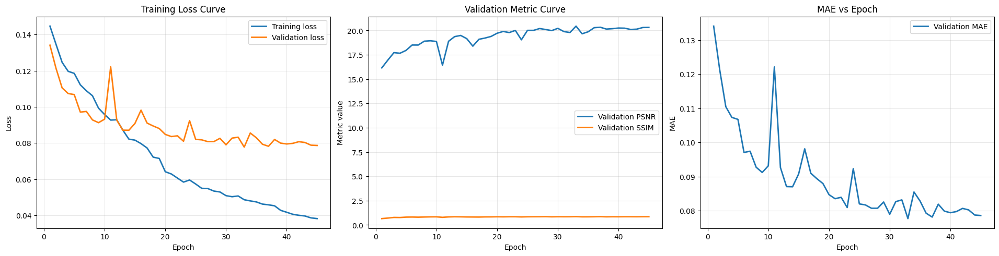

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), constrained_layout=True)
epochs = history["epoch"]
axes[0].plot(epochs, history["train_loss"], label="Training loss", linewidth=2)
axes[0].plot(epochs, history["val_loss"], label="Validation loss", linewidth=2)
axes[0].set(title="Training Loss Curve", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=.3); axes[0].legend()
axes[1].plot(epochs, history["val_psnr"], label="Validation PSNR", linewidth=2)
axes[1].plot(epochs, history["val_ssim"], label="Validation SSIM", linewidth=2)
axes[1].set(title="Validation Metric Curve", xlabel="Epoch", ylabel="Metric value")
axes[1].grid(alpha=.3); axes[1].legend()
axes[2].plot(epochs, history["val_mae"], label="Validation MAE", linewidth=2)
axes[2].set(title="MAE vs Epoch", xlabel="Epoch", ylabel="MAE")
axes[2].grid(alpha=.3); axes[2].legend()
plt.show()


## Test Protocol: NHD, RESIDE, and reside-6k
Every paired hazy image is dehazed and compared with its ground truth using PSNR, SSIM, MAE, and RMSE.


In [8]:
def dehaze_metrics(pred, gt):
    return {
        "PSNR": float(peak_signal_noise_ratio(gt, pred, data_range=1.0)),
        "SSIM": float(structural_similarity(gt, pred, channel_axis=-1, data_range=1.0)),
        "MAE": float(np.abs(pred.astype(np.float32) - gt.astype(np.float32)).mean()),
        "RMSE": float(np.sqrt(np.mean((pred.astype(np.float32) - gt.astype(np.float32)) ** 2))),
    }

def evaluate_dataset(model, dataset):
    records = []
    loader = make_loader(dataset)
    model.eval()
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Test {dataset.dataset_name}"):
            pred = model(batch["hazy"].to(device)).cpu()
            for i in range(pred.shape[0]):
                pred_np = pred[i].permute(1, 2, 0).numpy()
                gt_np = batch["gt"][i].permute(1, 2, 0).numpy()
                scores = dehaze_metrics(pred_np, gt_np)
                records.append({"dataset": dataset.dataset_name, "img_id": batch["img_id"][i], **scores})
    return pd.DataFrame(records)

reside_root = find_paired_root(cfg.RESIDE_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD",
    "/kaggle/input/reside-dataset-1/RESIDE_NHD/test",
    "/kaggle/input/reside/RESIDE_NHD/test",
])
reside6k_root = find_paired_root(cfg.RESIDE6K_ROOT, [
    "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset",
    "/kaggle/input/reside-6k-dataset/test",
    "/kaggle/input/reside6k-dataset/test",
])

test_datasets = {"NHD_dataset": test_dataset}
if reside_root:
    reside_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside_root, "hazy"), os.path.join(reside_root, "gt")), "RESIDE")
    if len(reside_dataset): test_datasets["RESIDE"] = reside_dataset
else:
    print("RESIDE not found; attach the dataset or update cfg.RESIDE_ROOT.")
if reside6k_root:
    reside6k_dataset = PairedDehazeDataset(build_image_pairs_from_folders(os.path.join(reside6k_root, "hazy"), os.path.join(reside6k_root, "gt")), "reside-6k")
    if len(reside6k_dataset): test_datasets["reside-6k"] = reside6k_dataset
else:
    print("reside-6k not found; attach the dataset or update cfg.RESIDE6K_ROOT.")

per_image_results = pd.concat([evaluate_dataset(model, ds) for ds in test_datasets.values()], ignore_index=True)
dataset_summary = per_image_results.groupby("dataset", as_index=False).agg(Images=("img_id", "count"), PSNR=("PSNR", "mean"), SSIM=("SSIM", "mean"), MAE=("MAE", "mean"), RMSE=("RMSE", "mean")).sort_values("dataset")
display(dataset_summary.style.format({"PSNR": "{:.4f}", "SSIM": "{:.4f}", "MAE": "{:.6f}", "RMSE": "{:.6f}"}))
per_image_results.to_csv(os.path.join(cfg.OUT_DIR, "ldformer_per_image_results.csv"), index=False)
dataset_summary.to_csv(os.path.join(cfg.OUT_DIR, "ldformer_dataset_summary.csv"), index=False)


Test NHD_dataset:   0%|          | 0/35 [00:00<?, ?it/s]

Test RESIDE:   0%|          | 0/100 [00:00<?, ?it/s]

Test reside-6k:   0%|          | 0/500 [00:00<?, ?it/s]

,dataset,Images,PSNR,SSIM,MAE,RMSE
0,NHD_dataset,70,20.7378,0.8355,0.074102,0.096062
1,RESIDE,200,17.2214,0.8007,0.119565,0.151923
2,reside-6k,1000,19.1524,0.8110,0.092584,0.118918


## PSNR Comparison


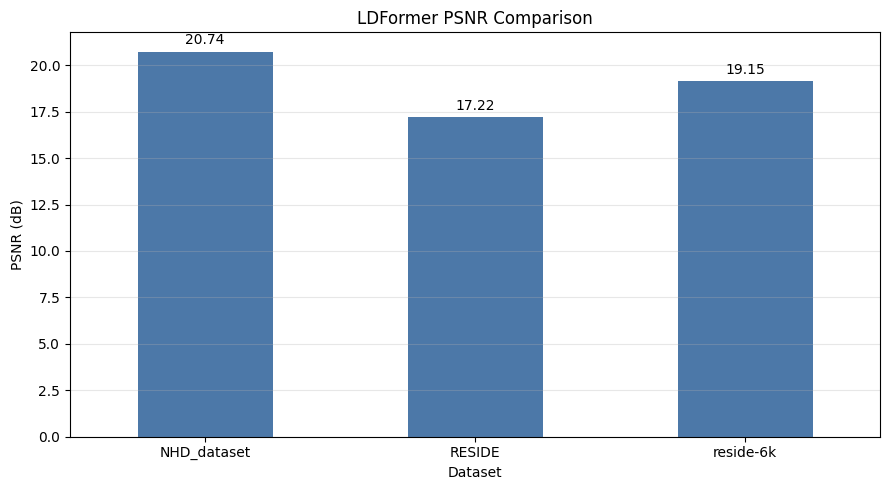

In [9]:
ax = dataset_summary.plot(x="dataset", y="PSNR", kind="bar", legend=False, figsize=(9, 5), color="#4C78A8")
ax.set(title="LDFormer PSNR Comparison", xlabel="Dataset", ylabel="PSNR (dB)")
ax.set_xticklabels(dataset_summary["dataset"], rotation=0)
ax.grid(axis="y", alpha=.3)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
plt.tight_layout(); plt.show()


## Subjective Visual Comparison
Show input haze, ground truth, LDFormer output, and an absolute-error map for every test dataset.


NHD_dataset


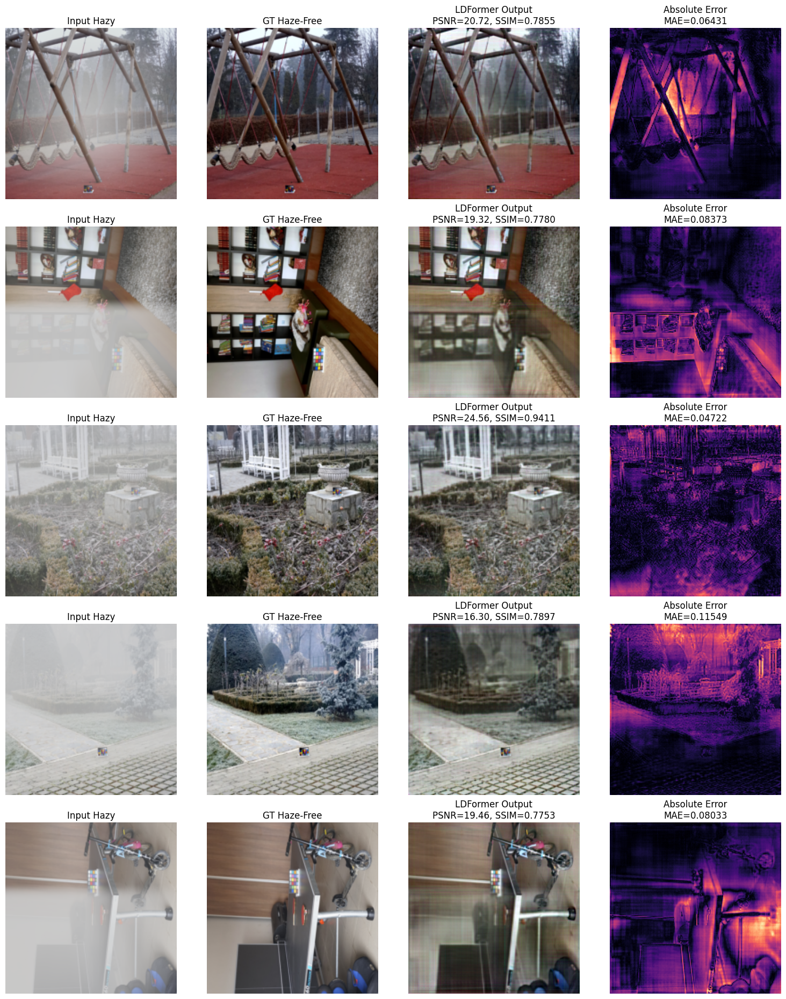

RESIDE


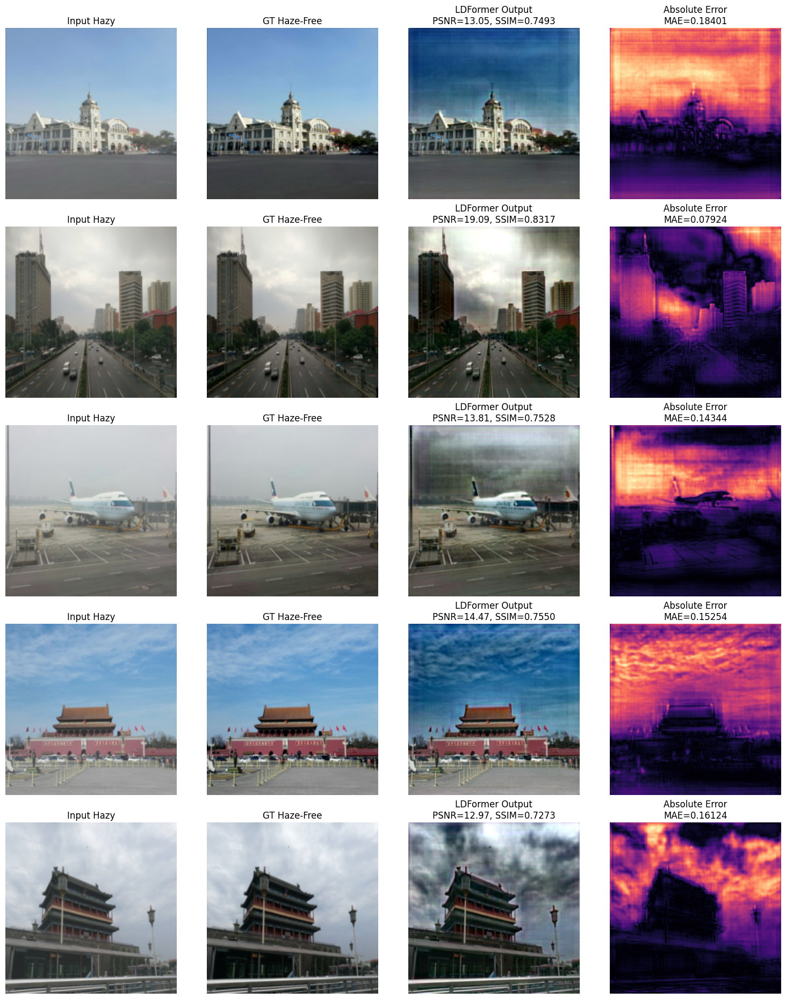

reside-6k


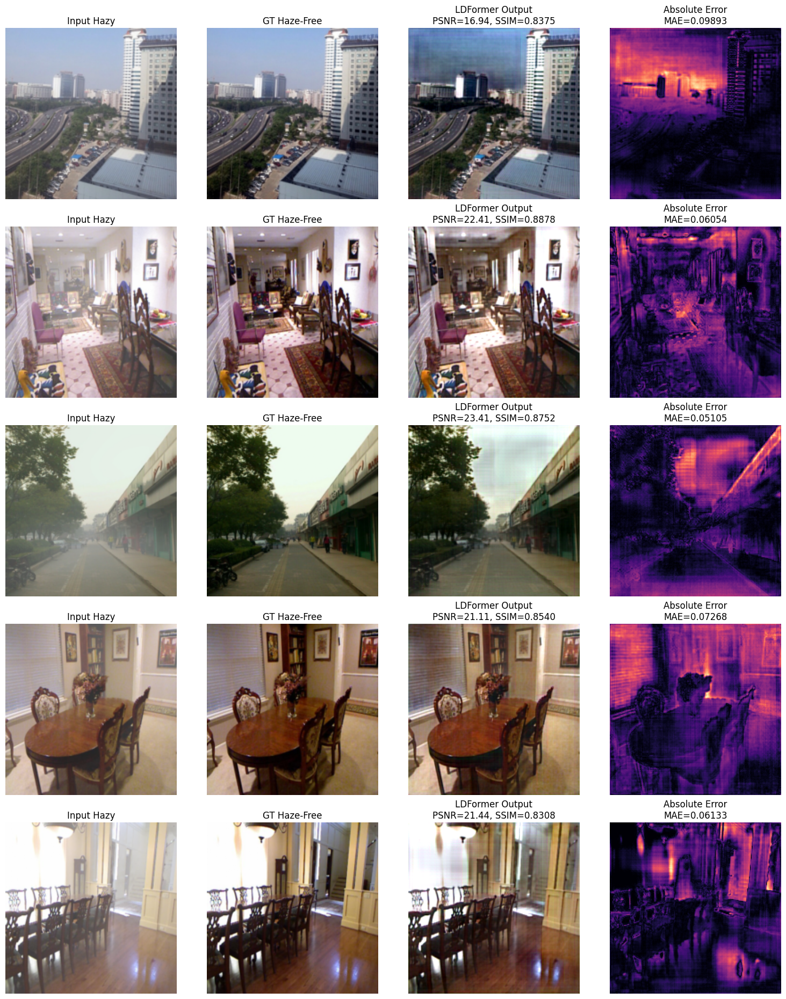

In [10]:
def show_subjective_comparison(model, dataset, n=5):
    model.eval()
    indices = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, axes = plt.subplots(len(indices), 4, figsize=(15, 3.7 * len(indices)), constrained_layout=True)
    if len(indices) == 1: axes = axes[None, :]
    with torch.no_grad():
        for row, idx in enumerate(indices):
            item = dataset[idx]
            hazy, gt = item["hazy"], item["gt"]
            pred = model(hazy.unsqueeze(0).to(device)).squeeze(0).cpu()
            hazy_np, gt_np, pred_np = [x.permute(1, 2, 0).numpy() for x in (hazy, gt, pred)]
            scores = dehaze_metrics(pred_np, gt_np)
            panels = [(hazy_np, "Input Hazy"), (gt_np, "GT Haze-Free"), (pred_np, f"LDFormer Output\nPSNR={scores['PSNR']:.2f}, SSIM={scores['SSIM']:.4f}"), (np.abs(pred_np - gt_np).mean(-1), f"Absolute Error\nMAE={scores['MAE']:.5f}")]
            for col, (image, title) in enumerate(panels):
                axes[row, col].imshow(image, cmap="magma" if col == 3 else None)
                axes[row, col].set_title(title); axes[row, col].axis("off")
    plt.show()

for name, dataset in test_datasets.items():
    print(name)
    show_subjective_comparison(model, dataset, n=5)


## Model Summary and Presentation Export


Model: HazeLightFormer
Trainable parameters: 965,673


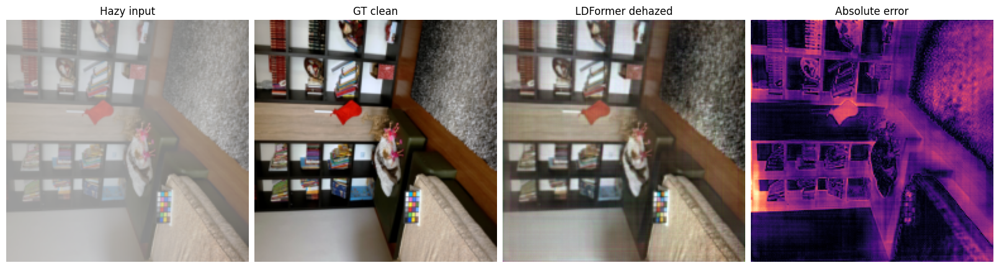

Saved: /kaggle/working/hazelightformer_nhd/ldformer_NHD_dataset_sample_000.png


,PSNR,SSIM,MAE,RMSE
0,19.7891,0.8201,0.0822,0.1025


In [11]:
def export_presentation_sample(model, dataset, sample_index=0, output_dir=None):
    output_dir = output_dir or cfg.OUT_DIR
    os.makedirs(output_dir, exist_ok=True)
    item = dataset[sample_index]
    model.eval()
    with torch.no_grad():
        pred = model(item["hazy"].unsqueeze(0).to(device)).squeeze(0).cpu()
    hazy, gt, pred = [x.permute(1, 2, 0).numpy() for x in (item["hazy"], item["gt"], pred)]
    error = np.abs(pred - gt).mean(-1)
    scores = dehaze_metrics(pred, gt)
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), constrained_layout=True)
    for ax, image, title in zip(axes, [hazy, gt, pred, error], ["Hazy input", "GT clean", "LDFormer dehazed", "Absolute error"]):
        ax.imshow(image, cmap="magma" if title == "Absolute error" else None)
        ax.set_title(title); ax.axis("off")
    path = os.path.join(output_dir, f"ldformer_{dataset.dataset_name}_sample_{sample_index:03d}.png")
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", path)
    display(pd.DataFrame([scores]).round(4))
    return path, scores

print(f"Model: {model.__class__.__name__}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
presentation_panel_path, presentation_sample_metrics = export_presentation_sample(model, test_dataset, sample_index=0)